# Iris Flower Classification — Model Evaluation

**Objective:** Train and compare Logistic Regression and Decision Tree classifiers on the provided Iris dataset, then evaluate them using a classification report and confusion-matrix heatmaps.

### Project review and improvements
- Uses the project-provided `data/iris.csv` file and its `species` target.
- Uses a **stratified train/test split** so all three species remain represented proportionally.
- Standardizes features for Logistic Regression inside a pipeline (fit only on training data), preventing data leakage.
- Reports precision, recall, F1-score, support, accuracy, macro averages and weighted averages.
- Plots a labeled confusion-matrix heatmap for each model and compares key metrics.
- Uses a fixed random seed so the split and results are reproducible.

**Dataset:** 150 samples, four numeric flower measurements, three classes (50 samples per class).

## 1. Import libraries

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

## 2. Load and validate the dataset
The notebook expects `data/iris.csv` next to the notebook in the project folder. If the notebook is moved, update `DATA_PATH` below.

In [2]:
PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "iris.csv"

# Also support running the notebook from the parent folder containing task_01_classification/
if not DATA_PATH.exists() and (PROJECT_DIR / "task_01_classification" / "data" / "iris.csv").exists():
    DATA_PATH = PROJECT_DIR / "task_01_classification" / "data" / "iris.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Place this notebook beside the data/ folder, "
        "or update DATA_PATH to point to iris.csv."
    )

df = pd.read_csv(DATA_PATH)
target_column = "species"

if target_column not in df.columns:
    raise ValueError(f"Expected target column '{target_column}' in the CSV.")
if df[target_column].isna().any():
    raise ValueError("Target column contains missing values.")
X = df.drop(columns=[target_column])
y = df[target_column].astype(str)

if X.isna().any().any():
    raise ValueError("Feature columns contain missing values. Clean/impute them before training.")
non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric:
    raise ValueError(f"Expected numeric feature columns; found: {non_numeric}")

print(f"Dataset shape: {df.shape}")
print(f"Feature columns: {X.columns.tolist()}")
print(f"Target column: {target_column}")
print(f"Missing values in dataset: {int(df.isna().sum().sum())}")
display(df.head())

Dataset shape: (150, 5)
Feature columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Target column: species
Missing values in dataset: 0


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory data analysis

Class counts:


,count
species,
setosa,50
versicolor,50
virginica,50


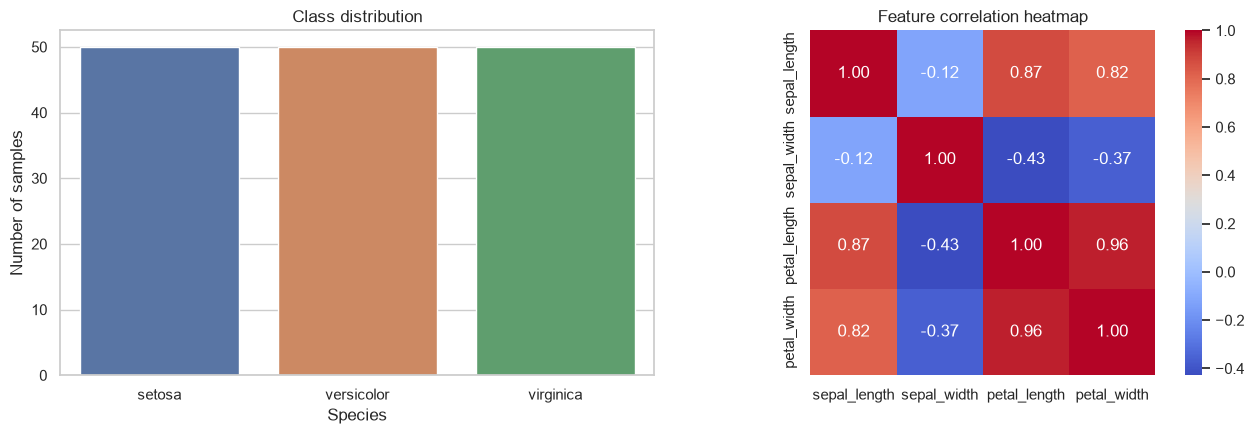

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


In [3]:
print("Class counts:")
display(y.value_counts().rename_axis("species").to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x=target_column, hue=target_column, legend=False, ax=axes[0])
axes[0].set_title("Class distribution")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Number of samples")

sns.heatmap(X.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f",
            square=True, ax=axes[1])
axes[1].set_title("Feature correlation heatmap")
plt.tight_layout()
plt.show()

display(df.describe().T)

## 4. Split the data
A stratified 80/20 split reserves a held-out test set for evaluation. The test set is not used to fit preprocessing or models.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Testing class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training samples: 120
Testing samples:  30

Training class proportions:


,proportion
species,
setosa,0.333333
versicolor,0.333333
virginica,0.333333


Testing class proportions:


,proportion
species,
setosa,0.333333
versicolor,0.333333
virginica,0.333333


## 5. Train classification models
Logistic Regression is wrapped in a pipeline so the scaler is fitted only on training data. Decision Tree does not require feature scaling.

In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        max_depth=None,
    ),
}

training_times = {}
for model_name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_times[model_name] = time.perf_counter() - start
    print(f"{model_name}: trained in {training_times[model_name]:.4f} seconds")

Logistic Regression: trained in 0.0127 seconds
Decision Tree: trained in 0.0022 seconds


## 6. Classification report and summary metrics
The per-class report includes precision, recall, F1-score and support. Macro averages treat each class equally; weighted averages account for the number of samples in each class.

In [6]:
class_labels = sorted(y.unique())
predictions = {}
reports = {}
summary_rows = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred
    reports[model_name] = classification_report(
        y_test, y_pred, labels=class_labels, output_dict=True, zero_division=0
    )

    print(f"\n{'=' * 22} {model_name} {'=' * 22}")
    print(classification_report(
        y_test, y_pred, labels=class_labels, target_names=class_labels,
        digits=4, zero_division=0
    ))

    summary_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, labels=class_labels, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, labels=class_labels, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, labels=class_labels, average="macro", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, y_pred, labels=class_labels, average="weighted", zero_division=0),
        "Training time (s)": training_times[model_name],
    })

metrics_df = pd.DataFrame(summary_rows).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
display(metrics_df.style.format({
    "Accuracy": "{:.4f}", "Precision (macro)": "{:.4f}", "Recall (macro)": "{:.4f}",
    "F1-score (macro)": "{:.4f}", "F1-score (weighted)": "{:.4f}", "Training time (s)": "{:.5f}"
}))


====================== Logistic Regression ======================
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30


====================== Decision Tree ======================
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),F1-score (weighted),Training time (s)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.01270
1,Decision Tree,0.9333,0.9333,0.9333,0.9333,0.9333,0.00215


## 7. Confusion matrix heatmaps
Rows represent the true class and columns represent the predicted class. Diagonal values are correct predictions; off-diagonal values are misclassifications.

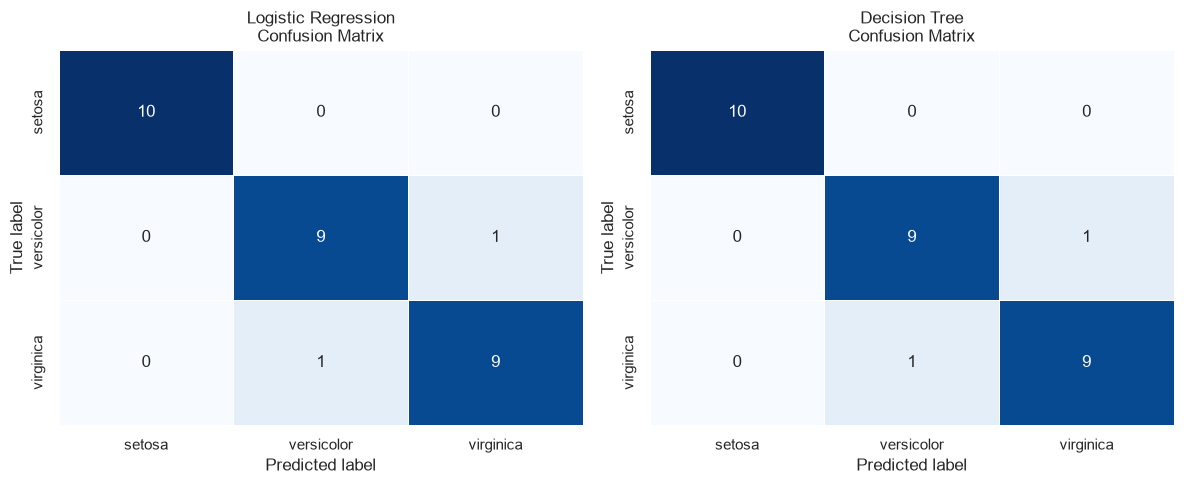

In [7]:
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5))
if len(models) == 1:
    axes = [axes]

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax,
        linewidths=0.5, linecolor="white",
    )
    ax.set_title(f"{model_name}\nConfusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

## 8. Compare model performance

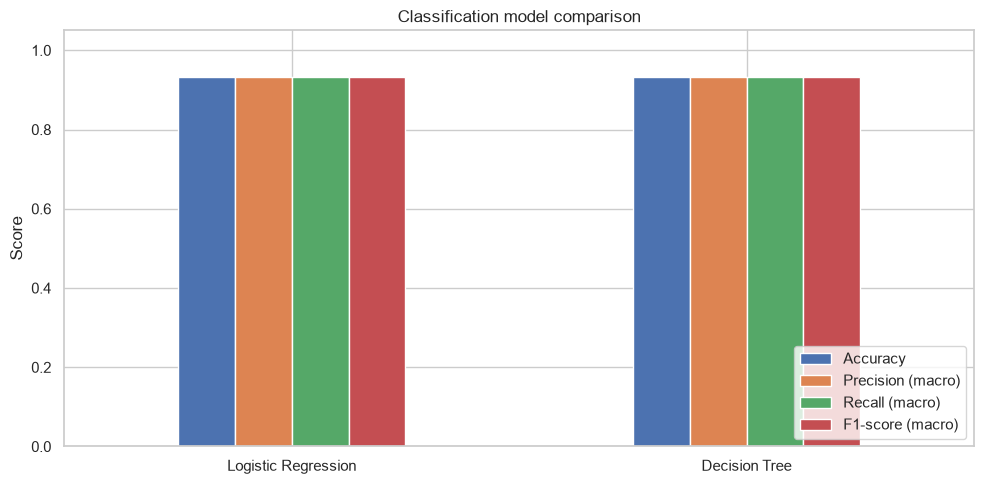

Best model by macro F1-score on this test split: Logistic Regression
Note: performance is based on one stratified hold-out split; cross-validation can provide a more robust estimate.


In [8]:
plot_metrics = metrics_df.set_index("Model")[[
    "Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"
]]
ax = plot_metrics.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05), rot=0)
ax.set_title("Classification model comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model_name = metrics_df.iloc[0]["Model"]
print(f"Best model by macro F1-score on this test split: {best_model_name}")
print("Note: performance is based on one stratified hold-out split; cross-validation can provide a more robust estimate.")

## 9. Conclusion

This notebook compares Logistic Regression and Decision Tree on the provided Iris dataset. Use the classification reports to inspect performance per species and the confusion-matrix heatmaps to see which species are confused with one another. The summary table ranks models by macro F1-score, which gives equal importance to each class.

**Limitations:** The Iris dataset is small and clean. Results on this dataset do not guarantee similar performance on other classification tasks. For a more robust estimate, add stratified cross-validation and evaluate on an independent dataset.